
# ACTIVIDAD FORMATIVA 3
## Implementación y evaluación de filtros digitales

**Asignatura:** Señales y Sistemas

**Estudiante:** Iris Sarahi Gutierrez Gamboa

**Actividad:** Diseño e implementación de filtros digitales.

**Herramienta de desarrollo:** Python y Jupyter Notebook.

**Librerías utilizadas:** NumPy, SciPy y Matplotlib.

---

### Objetivo general

Diseñar e implementar filtros digitales pasa bajos, pasa altos y pasa bandas mediante Python, aplicándolos a señales compuestas con ruido para analizar su comportamiento y evaluar su efectividad en el dominio del tiempo y la frecuencia.



# 1. Introducción

El procesamiento digital de señales es una técnica utilizada para analizar, modificar y mejorar señales mediante algoritmos computacionales. Una de sus aplicaciones más importantes es el uso de filtros digitales, los cuales permiten seleccionar determinadas frecuencias y reducir aquellas que pueden afectar la calidad de una señal.

Los filtros digitales son utilizados en diferentes áreas, como las telecomunicaciones, el procesamiento de audio, los sistemas de control y el análisis de señales biomédicas.

En esta actividad se implementarán tres tipos de filtros digitales: pasa bajos, pasa altos y pasa bandas, utilizando Python y las librerías NumPy, SciPy y Matplotlib.

Se generará una señal compuesta por diferentes frecuencias y ruido blanco, sobre la cual se aplicarán los filtros para observar sus efectos. Posteriormente, se compararán las señales originales y filtradas mediante gráficas en el dominio del tiempo y de la frecuencia, con el propósito de evaluar el comportamiento y la efectividad de cada filtro.

## 1.1 Tipos de filtros digitales

### Filtro pasa bajos

Permite el paso de las frecuencias inferiores a una frecuencia de corte determinada, mientras atenúa las frecuencias superiores. Se utiliza para reducir componentes de alta frecuencia y suavizar señales.

### Filtro pasa altos

Permite el paso de las frecuencias superiores a una frecuencia de corte, mientras atenúa las frecuencias inferiores. Se utiliza para eliminar componentes de baja frecuencia.

### Filtro pasa bandas

Permite el paso de las frecuencias comprendidas dentro de un rango específico, atenuando aquellas que se encuentran por debajo y por encima de dicho rango.

## 1.2 Respuesta en frecuencia

La respuesta en frecuencia permite conocer cómo se comporta un filtro ante las diferentes frecuencias de una señal. Mediante una gráfica es posible identificar las frecuencias que pasan a través del filtro y aquellas que son atenuadas.

Este análisis es fundamental para evaluar la efectividad de los filtros digitales implementados.


In [1]:

# =====================================================
# 2. IMPORTACIÓN DE LIBRERÍAS
# Actividad: Implementación y evaluación de filtros digitales
# =====================================================

# NumPy: operaciones matemáticas y manejo de señales
import numpy as np

# Pandas: organización y análisis de datos
import pandas as pd

# Matplotlib: generación de gráficas
import matplotlib.pyplot as plt

# SciPy: diseño y procesamiento de filtros digitales
from scipy import signal

# Mostrar versiones de las librerías instaladas
print("======================================")
print(" ENTORNO DE DESARROLLO CONFIGURADO")
print("======================================")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", __import__('scipy').__version__)
print("Matplotlib:", plt.matplotlib.__version__)

print("\nTodas las librerías se importaron correctamente.")


Matplotlib is building the font cache; this may take a moment.


 ENTORNO DE DESARROLLO CONFIGURADO
NumPy: 2.5.5
Pandas: 3.1.1
SciPy: 1.18.1
Matplotlib: 3.11.2

Todas las librerías se importaron correctamente.



# 2. Configuración de los parámetros de simulación

Para realizar las pruebas se establecerán los parámetros necesarios para generar una señal compuesta por tres componentes de diferentes frecuencias.

Se utilizará una frecuencia de muestreo de 1000 Hz y una duración de 2 segundos. Las frecuencias seleccionadas serán 5 Hz, 50 Hz y 120 Hz.

Estos valores permitirán evaluar el comportamiento de los filtros pasa bajos, pasa altos y pasa bandas.


In [2]:

# =====================================================
# 3. CONFIGURACIÓN DE LOS PARÁMETROS DE SIMULACIÓN
# =====================================================

# Frecuencia de muestreo (Hz)
frecuencia_muestreo = 1000

# Duración de la señal (segundos)
duracion = 2

# Frecuencias de los componentes de la señal (Hz)
frecuencia_1 = 5
frecuencia_2 = 50
frecuencia_3 = 120

# Crear el vector de tiempo
tiempo = np.arange(
    0,
    duracion,
    1 / frecuencia_muestreo
)

# Mostrar los parámetros configurados
print("======================================")
print(" PARÁMETROS DE LA SIMULACIÓN")
print("======================================")

print(f"Frecuencia de muestreo: {frecuencia_muestreo} Hz")
print(f"Duración: {duracion} segundos")
print(f"Frecuencia 1: {frecuencia_1} Hz")
print(f"Frecuencia 2: {frecuencia_2} Hz")
print(f"Frecuencia 3: {frecuencia_3} Hz")
print(f"Número de muestras: {len(tiempo)}")


 PARÁMETROS DE LA SIMULACIÓN
Frecuencia de muestreo: 1000 Hz
Duración: 2 segundos
Frecuencia 1: 5 Hz
Frecuencia 2: 50 Hz
Frecuencia 3: 120 Hz
Número de muestras: 2000



# 3. Generación de la señal original

Para evaluar el funcionamiento de los filtros digitales, se generará una señal compuesta por tres ondas senoidales de diferentes frecuencias: 5 Hz, 50 Hz y 120 Hz.

Posteriormente, se agregará ruido blanco mediante valores aleatorios para simular interferencias que pueden presentarse durante la adquisición de una señal.

La señal resultante será utilizada como entrada para los filtros pasa bajos, pasa altos y pasa bandas.


In [3]:

# =====================================================
# 4. GENERACIÓN DE LAS SEÑALES INDIVIDUALES
# =====================================================

# Generar señal senoidal de 5 Hz
senal_1 = np.sin(2 * np.pi * frecuencia_1 * tiempo)

# Generar señal senoidal de 50 Hz
senal_2 = np.sin(2 * np.pi * frecuencia_2 * tiempo)

# Generar señal senoidal de 120 Hz
senal_3 = np.sin(2 * np.pi * frecuencia_3 * tiempo)

print("Señales individuales generadas correctamente.")


Señales individuales generadas correctamente.


In [4]:

# =====================================================
# 5. GENERACIÓN DE RUIDO Y SEÑAL COMPUESTA
# =====================================================

# Establecer semilla para reproducir los mismos resultados
np.random.seed(42)

# Generar ruido blanco aleatorio
ruido = np.random.normal(
    loc=0,
    scale=0.5,
    size=len(tiempo)
)

# Combinar las tres señales y el ruido
senal_original = senal_1 + senal_2 + senal_3 + ruido

print("Señal compuesta generada correctamente.")
print("Cantidad de muestras:", len(senal_original))
print("Amplitud máxima:", round(np.max(senal_original), 3))
print("Amplitud mínima:", round(np.min(senal_original), 3))


Señal compuesta generada correctamente.
Cantidad de muestras: 2000
Amplitud máxima: 3.393
Amplitud mínima: -3.983


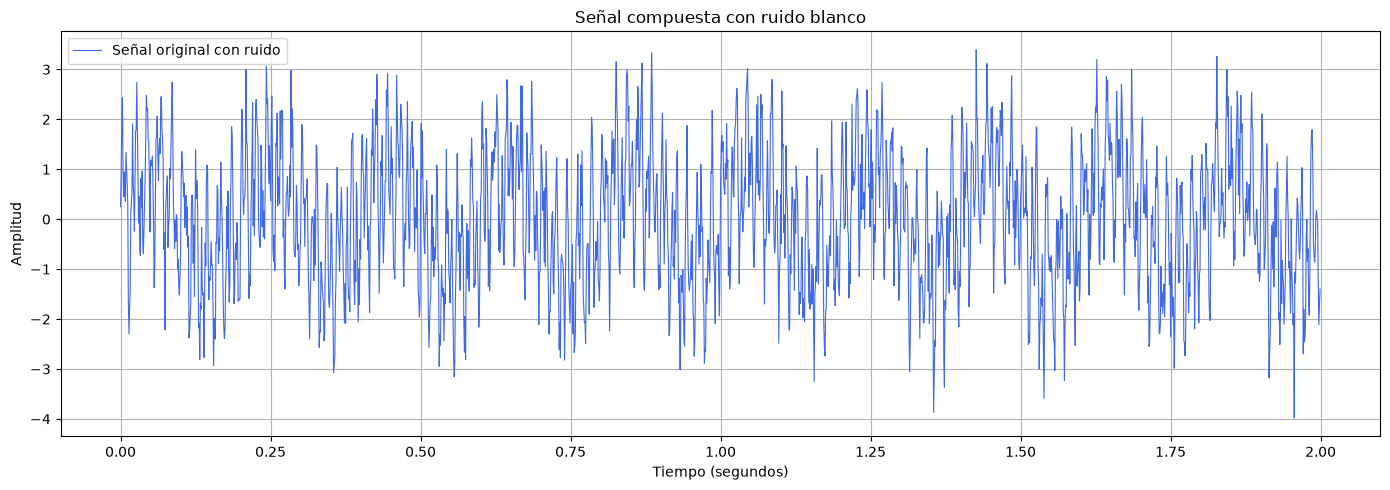

In [5]:

# =====================================================
# 6. VISUALIZACIÓN DE LA SEÑAL ORIGINAL
# =====================================================

plt.figure(figsize=(14, 5))

plt.plot(
    tiempo,
    senal_original,
    color="royalblue",
    linewidth=0.8,
    label="Señal original con ruido"
)

plt.title("Señal compuesta con ruido blanco")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



# 4. Diseño e implementación del filtro pasa bajos

El filtro pasa bajos permite conservar las frecuencias inferiores a una frecuencia de corte determinada y atenuar las frecuencias superiores.

Para esta simulación se utilizará un filtro Butterworth de cuarto orden, con una frecuencia de corte de 30 Hz.

El objetivo es conservar principalmente el componente de 5 Hz y reducir los componentes de 50 Hz, 120 Hz y parte del ruido de alta frecuencia.

Se utilizará la función `sosfiltfilt` de SciPy para aplicar el filtrado en ambas direcciones y evitar el desfase de fase en la señal resultante.


In [6]:

# =====================================================
# 7. DISEÑO DEL FILTRO PASA BAJOS
# =====================================================

# Definir frecuencia de corte
frecuencia_corte_bajos = 30

# Definir orden del filtro
orden_filtro = 4

# Diseñar filtro Butterworth pasa bajos
sos_bajos = signal.butter(
    orden_filtro,
    frecuencia_corte_bajos,
    btype='lowpass',
    fs=frecuencia_muestreo,
    output='sos'
)

print("Filtro pasa bajos diseñado correctamente.")
print("Tipo de filtro: Butterworth")
print("Orden:", orden_filtro)
print("Frecuencia de corte:", frecuencia_corte_bajos, "Hz")


Filtro pasa bajos diseñado correctamente.
Tipo de filtro: Butterworth
Orden: 4
Frecuencia de corte: 30 Hz


In [7]:

# =====================================================
# 8. APLICACIÓN DEL FILTRO PASA BAJOS
# =====================================================

# Aplicar el filtro a la señal original
senal_pasa_bajos = signal.sosfiltfilt(
    sos_bajos,
    senal_original
)

print("Filtro pasa bajos aplicado correctamente.")


Filtro pasa bajos aplicado correctamente.


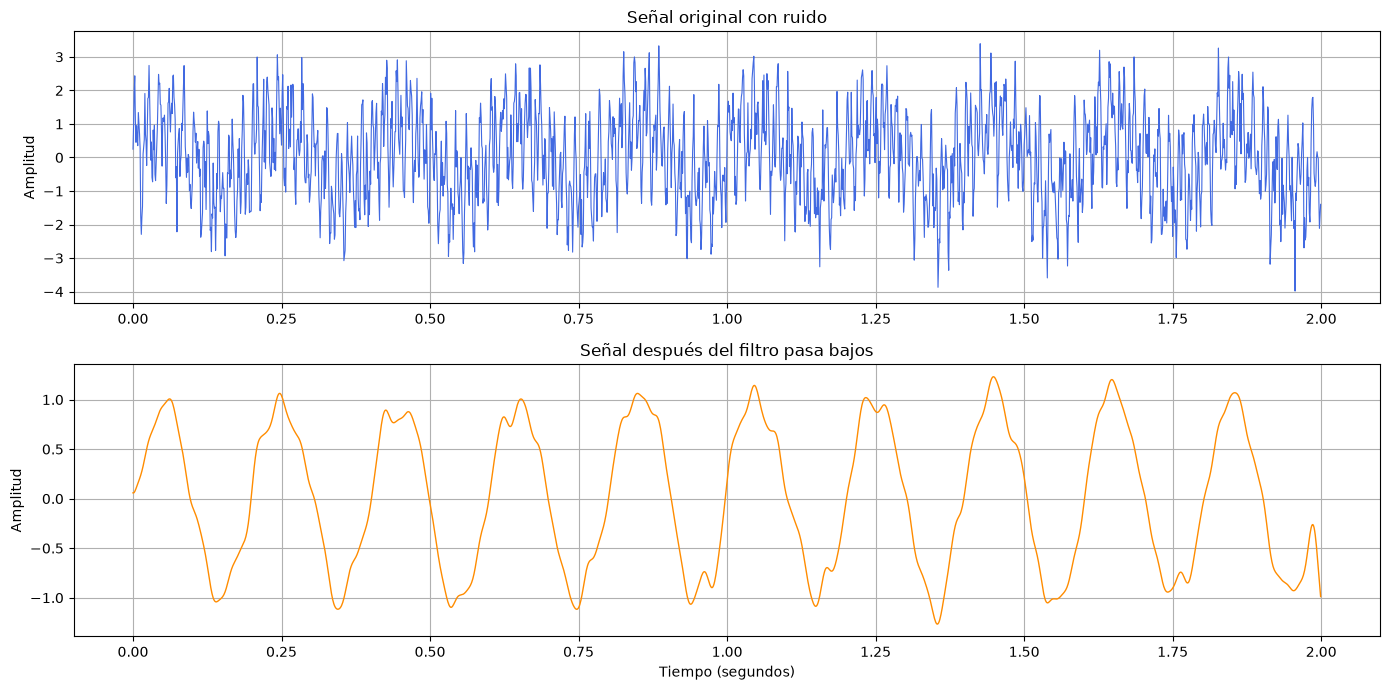

In [8]:

# =====================================================
# 9. COMPARACIÓN: SEÑAL ORIGINAL VS PASA BAJOS
# =====================================================

plt.figure(figsize=(14, 7))

# Señal original
plt.subplot(2, 1, 1)
plt.plot(tiempo, senal_original, color='royalblue',
         linewidth=0.8)
plt.title("Señal original con ruido")
plt.ylabel("Amplitud")
plt.grid(True)

# Señal filtrada
plt.subplot(2, 1, 2)
plt.plot(tiempo, senal_pasa_bajos, color='darkorange',
         linewidth=1)
plt.title("Señal después del filtro pasa bajos")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()



### 4.1 Análisis de resultados del filtro pasa bajos

Al aplicar el filtro Butterworth pasa bajos con una frecuencia de corte de 30 Hz, se observa una reducción considerable de las oscilaciones rápidas presentes en la señal original.

La señal filtrada conserva principalmente la componente de 5 Hz, mientras que las frecuencias de 50 Hz y 120 Hz son atenuadas.

También se observa una reducción del ruido blanco, debido a que una parte importante de sus componentes de alta frecuencia es eliminada.

Los resultados permiten comprobar que el filtro pasa bajos es efectivo para conservar las frecuencias bajas y reducir las frecuencias superiores a su frecuencia de corte.



# 5. Diseño e implementación del filtro pasa altos

El filtro pasa altos permite conservar las frecuencias superiores a una frecuencia de corte determinada y atenuar las frecuencias inferiores.

Para esta simulación se utilizará un filtro Butterworth de cuarto orden, con una frecuencia de corte de 70 Hz.

El objetivo es reducir principalmente las componentes de 5 Hz y 50 Hz, conservando la componente de 120 Hz.

Se utilizará la función `sosfiltfilt` de SciPy para aplicar el filtrado en ambas direcciones y evitar el desfase de fase en la señal resultante.


In [9]:

# =====================================================
# 10. DISEÑO DEL FILTRO PASA ALTOS
# =====================================================

# Definir frecuencia de corte
frecuencia_corte_altos = 70

# Diseñar filtro Butterworth pasa altos
sos_altos = signal.butter(
    orden_filtro,
    frecuencia_corte_altos,
    btype='highpass',
    fs=frecuencia_muestreo,
    output='sos'
)

print("Filtro pasa altos diseñado correctamente.")
print("Tipo de filtro: Butterworth")
print("Orden:", orden_filtro)
print("Frecuencia de corte:", frecuencia_corte_altos, "Hz")


Filtro pasa altos diseñado correctamente.
Tipo de filtro: Butterworth
Orden: 4
Frecuencia de corte: 70 Hz


In [10]:

# =====================================================
# 11. APLICACIÓN DEL FILTRO PASA ALTOS
# =====================================================

# Aplicar el filtro a la señal original
senal_pasa_altos = signal.sosfiltfilt(
    sos_altos,
    senal_original
)

print("Filtro pasa altos aplicado correctamente.")


Filtro pasa altos aplicado correctamente.


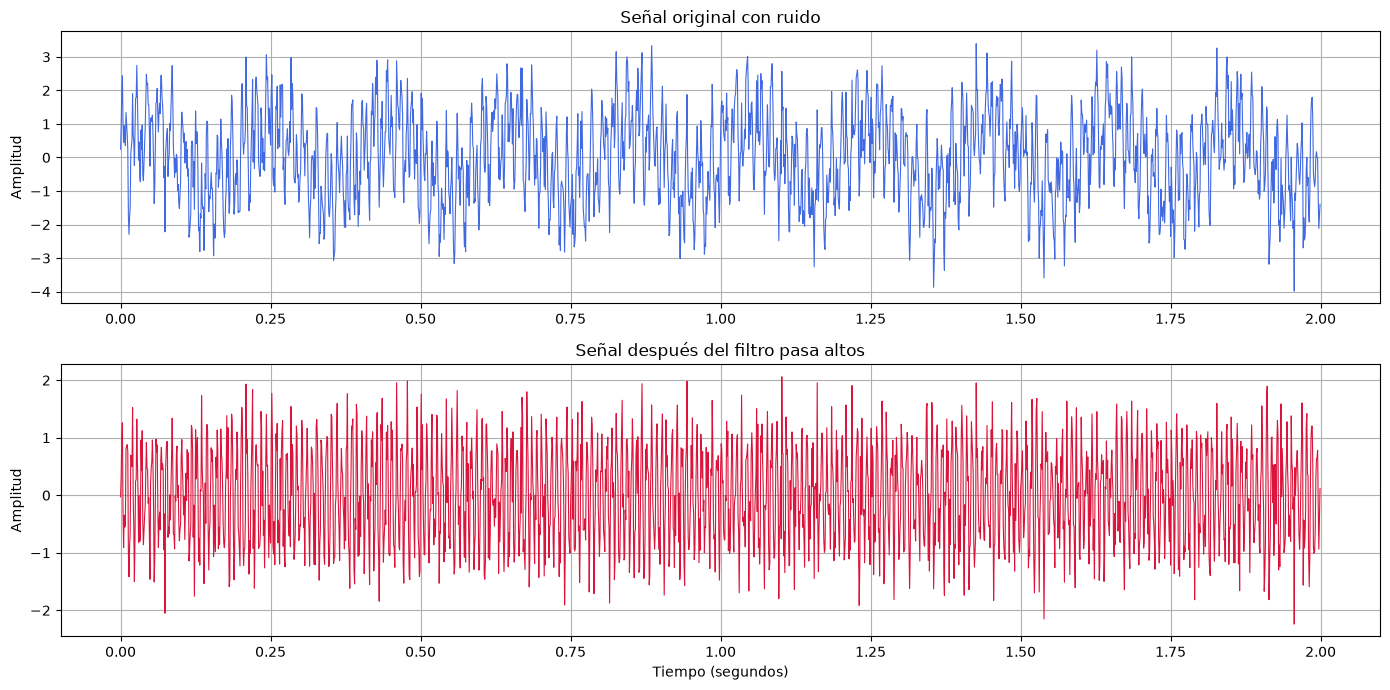

In [11]:

# =====================================================
# 12. COMPARACIÓN: SEÑAL ORIGINAL VS PASA ALTOS
# =====================================================

plt.figure(figsize=(14, 7))

# Señal original
plt.subplot(2, 1, 1)
plt.plot(tiempo, senal_original, color='royalblue',
         linewidth=0.8)
plt.title("Señal original con ruido")
plt.ylabel("Amplitud")
plt.grid(True)

# Señal filtrada
plt.subplot(2, 1, 2)
plt.plot(tiempo, senal_pasa_altos, color='crimson',
         linewidth=0.8)
plt.title("Señal después del filtro pasa altos")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()



### 5.1 Análisis de resultados del filtro pasa altos

Al aplicar el filtro Butterworth pasa altos con una frecuencia de corte de 70 Hz, se observa que las oscilaciones de baja frecuencia disminuyen considerablemente.

La componente de 5 Hz es atenuada, al igual que la componente de 50 Hz, mientras que la frecuencia de 120 Hz se conserva principalmente.

En la gráfica de la señal filtrada se pueden observar oscilaciones más rápidas, correspondientes a las componentes de mayor frecuencia.

Los resultados demuestran que el filtro pasa altos permite seleccionar las frecuencias superiores a su frecuencia de corte y reducir las componentes de baja frecuencia.



# 6. Diseño e implementación del filtro pasa bandas

El filtro pasa bandas permite conservar las frecuencias comprendidas dentro de un intervalo determinado, mientras atenúa las frecuencias inferiores y superiores a dicho rango.

Para esta simulación se utilizará un filtro Butterworth de cuarto orden, con una frecuencia de corte inferior de 40 Hz y una frecuencia de corte superior de 60 Hz.

El objetivo es conservar principalmente la componente de 50 Hz y reducir las componentes de 5 Hz y 120 Hz.

Se utilizará la función `sosfiltfilt` de SciPy para aplicar el filtrado en ambas direcciones y evitar el desfase de fase en la señal resultante.


In [12]:

# =====================================================
# 13. DISEÑO DEL FILTRO PASA BANDAS
# =====================================================

# Definir frecuencias de corte
frecuencia_corte_inferior = 40
frecuencia_corte_superior = 60

# Diseñar filtro Butterworth pasa bandas
sos_bandas = signal.butter(
    orden_filtro,
    [frecuencia_corte_inferior, frecuencia_corte_superior],
    btype='bandpass',
    fs=frecuencia_muestreo,
    output='sos'
)

print("Filtro pasa bandas diseñado correctamente.")
print("Tipo de filtro: Butterworth")
print("Orden: ", orden_filtro)
print("Frecuencia inferior:", frecuencia_corte_inferior, "Hz")
print("Frecuencia superior:", frecuencia_corte_superior, "Hz")


Filtro pasa bandas diseñado correctamente.
Tipo de filtro: Butterworth
Orden:  4
Frecuencia inferior: 40 Hz
Frecuencia superior: 60 Hz


In [13]:

# =====================================================
# 14. APLICACIÓN DEL FILTRO PASA BANDAS
# =====================================================

# Aplicar el filtro a la señal original
senal_pasa_bandas = signal.sosfiltfilt(
    sos_bandas,
    senal_original
)

print("Filtro pasa bandas aplicado correctamente.")


Filtro pasa bandas aplicado correctamente.


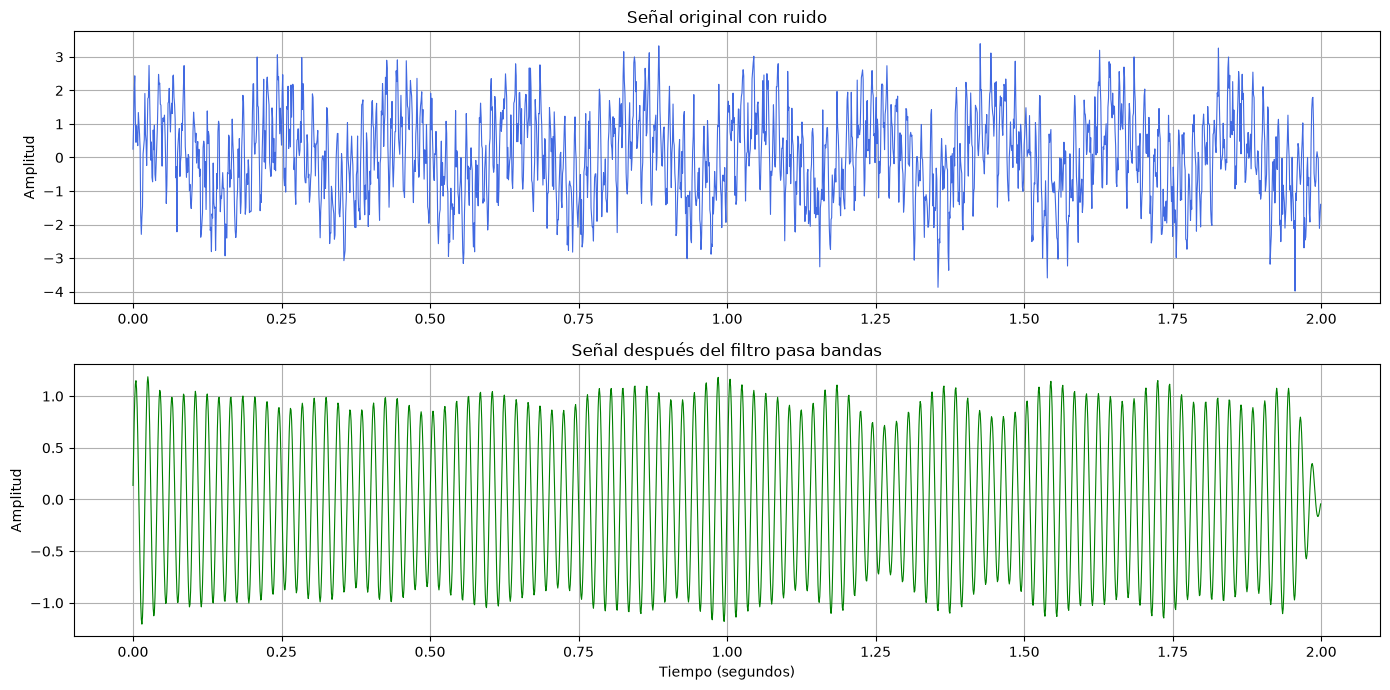

In [14]:

# =====================================================
# 15. COMPARACIÓN: SEÑAL ORIGINAL VS PASA BANDAS
# =====================================================

plt.figure(figsize=(14, 7))

# Señal original
plt.subplot(2, 1, 1)
plt.plot(tiempo, senal_original, color='royalblue',
         linewidth=0.8)
plt.title("Señal original con ruido")
plt.ylabel("Amplitud")
plt.grid(True)

# Señal filtrada
plt.subplot(2, 1, 2)
plt.plot(tiempo, senal_pasa_bandas, color='green',
         linewidth=0.8)
plt.title("Señal después del filtro pasa bandas")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()



### 6.1 Análisis de resultados del filtro pasa bandas

Al aplicar el filtro Butterworth pasa bandas con frecuencias de corte de 40 Hz y 60 Hz, se observa que la señal resultante conserva principalmente la componente de 50 Hz.

Las frecuencias de 5 Hz y 120 Hz son atenuadas considerablemente, debido a que se encuentran fuera del intervalo establecido.

La gráfica muestra una señal con oscilaciones más regulares, lo que permite identificar la frecuencia seleccionada por el filtro.

Los resultados demuestran que el filtro pasa bandas es útil para seleccionar un intervalo específico de frecuencias dentro de una señal compuesta.



# 7. Comparación de los filtros digitales

En esta sección se comparan los resultados obtenidos al aplicar los filtros pasa bajos, pasa altos y pasa bandas sobre una misma señal original.

El propósito es identificar las diferencias entre las señales filtradas y comprobar qué componentes de frecuencia conserva cada filtro.


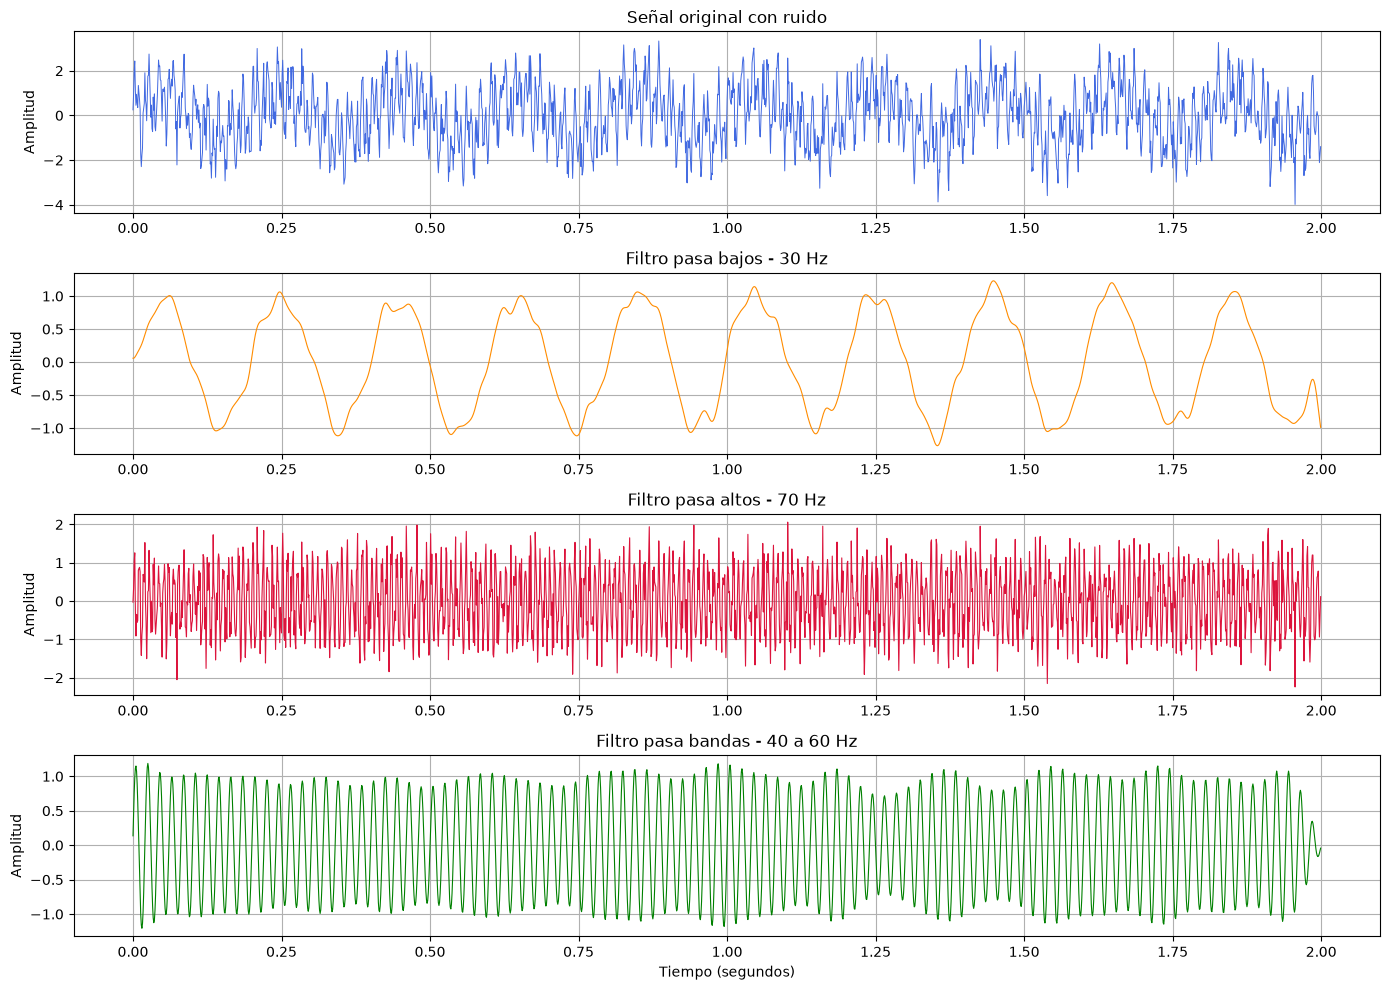

In [15]:

# =====================================================
# 16. COMPARACIÓN DE LOS TRES FILTROS DIGITALES
# =====================================================

plt.figure(figsize=(14, 10))

# Señal original
plt.subplot(4, 1, 1)
plt.plot(tiempo, senal_original, color='royalblue',
         linewidth=0.7)
plt.title("Señal original con ruido")
plt.ylabel("Amplitud")
plt.grid(True)

# Filtro pasa bajos
plt.subplot(4, 1, 2)
plt.plot(tiempo, senal_pasa_bajos, color='darkorange',
         linewidth=0.8)
plt.title("Filtro pasa bajos - 30 Hz")
plt.ylabel("Amplitud")
plt.grid(True)

# Filtro pasa altos
plt.subplot(4, 1, 3)
plt.plot(tiempo, senal_pasa_altos, color='crimson',
         linewidth=0.8)
plt.title("Filtro pasa altos - 70 Hz")
plt.ylabel("Amplitud")
plt.grid(True)

# Filtro pasa bandas
plt.subplot(4, 1, 4)
plt.plot(tiempo, senal_pasa_bandas, color='green',
         linewidth=0.8)
plt.title("Filtro pasa bandas - 40 a 60 Hz")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()



### 7.1 Análisis comparativo

Los resultados obtenidos permiten identificar el comportamiento de cada filtro digital.

El filtro pasa bajos permitió conservar principalmente las frecuencias bajas, reduciendo las componentes superiores a 30 Hz.

El filtro pasa altos atenuó las frecuencias inferiores a 70 Hz y conservó principalmente la componente de 120 Hz.

Por su parte, el filtro pasa bandas permitió seleccionar el intervalo de 40 a 60 Hz, conservando principalmente la componente de 50 Hz.

En general, los tres filtros cumplieron con su función de seleccionar diferentes componentes de frecuencia de la señal original.



# 8. Análisis de la respuesta en frecuencia

La respuesta en frecuencia permite analizar el comportamiento de un filtro digital ante diferentes frecuencias de entrada.

Mediante esta representación es posible identificar las frecuencias que pasan a través del filtro y aquellas que son atenuadas.

En esta actividad se analizará la respuesta en frecuencia de los filtros Butterworth pasa bajos, pasa altos y pasa bandas, utilizando las funciones de análisis de SciPy.

Se utilizarán gráficas de magnitud expresadas en decibelios (dB) para comparar el comportamiento de los tres filtros.


In [16]:

# =====================================================
# 17. CÁLCULO DE LAS RESPUESTAS EN FRECUENCIA
# =====================================================

# Respuesta del filtro pasa bajos
frecuencias_bajos, respuesta_bajos = signal.sosfreqz(
    sos_bajos,
    worN=2048,
    fs=frecuencia_muestreo
)

# Respuesta del filtro pasa altos
frecuencias_altos, respuesta_altos = signal.sosfreqz(
    sos_altos,
    worN=2048,
    fs=frecuencia_muestreo
)

# Respuesta del filtro pasa bandas
frecuencias_bandas, respuesta_bandas = signal.sosfreqz(
    sos_bandas,
    worN=2048,
    fs=frecuencia_muestreo
)

# Convertir magnitud a decibelios
magnitud_bajos = 20 * np.log10(
    np.maximum(np.abs(respuesta_bajos), 1e-10)
)

magnitud_altos = 20 * np.log10(
    np.maximum(np.abs(respuesta_altos), 1e-10)
)

magnitud_bandas = 20 * np.log10(
    np.maximum(np.abs(respuesta_bandas), 1e-10)
)

print("Respuestas en frecuencia calculadas correctamente.")


Respuestas en frecuencia calculadas correctamente.


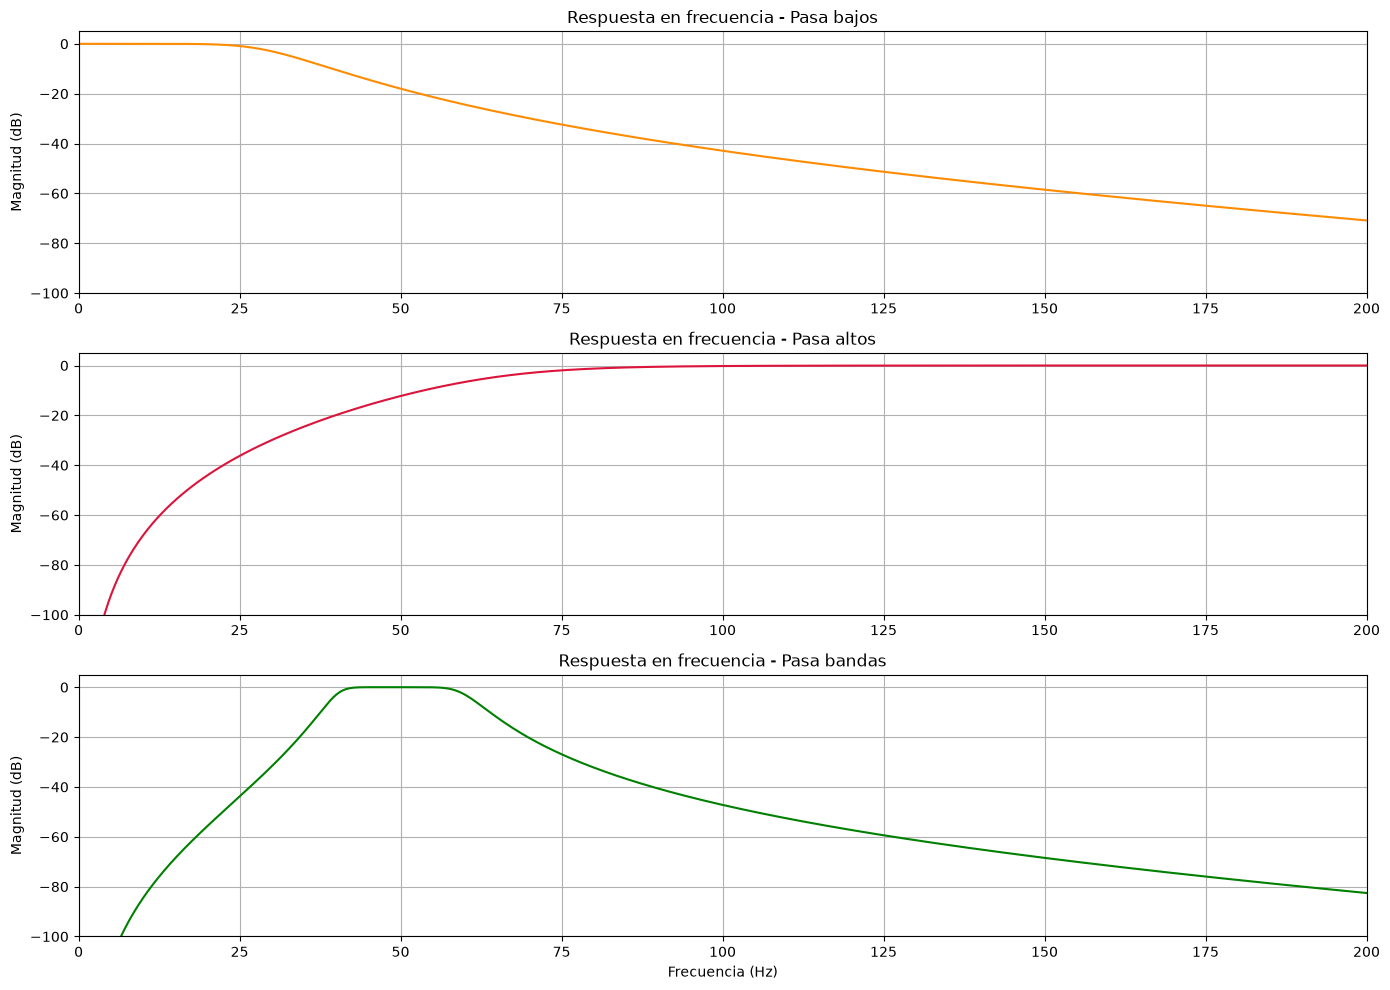

In [17]:

# =====================================================
# 18. GRÁFICAS DE RESPUESTA EN FRECUENCIA
# =====================================================

plt.figure(figsize=(14, 10))

# Filtro pasa bajos
plt.subplot(3, 1, 1)
plt.plot(frecuencias_bajos, magnitud_bajos,
         color='darkorange')
plt.title("Respuesta en frecuencia - Pasa bajos")
plt.ylabel("Magnitud (dB)")
plt.xlim(0, 200)
plt.ylim(-100, 5)
plt.grid(True)

# Filtro pasa altos
plt.subplot(3, 1, 2)
plt.plot(frecuencias_altos, magnitud_altos,
         color='crimson')
plt.title("Respuesta en frecuencia - Pasa altos")
plt.ylabel("Magnitud (dB)")
plt.xlim(0, 200)
plt.ylim(-100, 5)
plt.grid(True)

# Filtro pasa bandas
plt.subplot(3, 1, 3)
plt.plot(frecuencias_bandas, magnitud_bandas,
         color='green')
plt.title("Respuesta en frecuencia - Pasa bandas")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud (dB)")
plt.xlim(0, 200)
plt.ylim(-100, 5)
plt.grid(True)

plt.tight_layout()
plt.show()



### 8.1 Interpretación de las respuestas en frecuencia

Las gráficas obtenidas permiten analizar el comportamiento de los tres filtros digitales implementados.

**Filtro pasa bajos:**

La respuesta en frecuencia muestra que el filtro conserva las componentes de baja frecuencia y atenúa progresivamente las frecuencias superiores a 30 Hz.

**Filtro pasa altos:**

Se observa que las frecuencias inferiores a 70 Hz presentan una mayor atenuación, mientras que las frecuencias superiores se conservan con una magnitud cercana a 0 dB.

**Filtro pasa bandas:**

La gráfica muestra una región de paso comprendida entre 40 y 60 Hz. Las frecuencias externas a este intervalo presentan una atenuación considerable.

En conclusión, las respuestas en frecuencia confirman que los tres filtros cumplen con el comportamiento esperado según su diseño y sus respectivas frecuencias de corte.



# 9. Evaluación cuantitativa de los filtros

Para complementar el análisis gráfico, se realizará una evaluación cuantitativa de las señales originales y filtradas.

Se utilizará el valor RMS (Root Mean Square) para medir el nivel efectivo de amplitud de cada señal.

También se calculará la reducción porcentual del RMS y se analizará la amplitud de las componentes de 5 Hz, 50 Hz y 120 Hz después de aplicar cada filtro.

Estos indicadores permitirán comparar numéricamente el comportamiento de los filtros digitales.


In [18]:

# =====================================================
# 19. CÁLCULO DEL VALOR RMS
# =====================================================

# Función para calcular RMS
def calcular_rms(senal):
    return np.sqrt(np.mean(senal ** 2))

# Calcular RMS de cada señal
rms_original = calcular_rms(senal_original)
rms_bajos = calcular_rms(senal_pasa_bajos)
rms_altos = calcular_rms(senal_pasa_altos)
rms_bandas = calcular_rms(senal_pasa_bandas)

# Mostrar resultados
print("========== VALORES RMS ==========")

print(f"Señal original: {rms_original:.4f}")
print(f"Filtro pasa bajos: {rms_bajos:.4f}")
print(f"Filtro pasa altos: {rms_altos:.4f}")
print(f"Filtro pasa bandas: {rms_bandas:.4f}")


========== VALORES RMS ==========
Señal original: 1.3203
Filtro pasa bajos: 0.7262
Filtro pasa altos: 0.8370
Filtro pasa bandas: 0.6955


In [19]:

# =====================================================
# 20. REDUCCIÓN PORCENTUAL DEL RMS
# =====================================================

# Calcular reducción respecto a la señal original
reduccion_bajos = (
    (1 - rms_bajos / rms_original) * 100
)

reduccion_altos = (
    (1 - rms_altos / rms_original) * 100
)

reduccion_bandas = (
    (1 - rms_bandas / rms_original) * 100
)

print("====== REDUCCIÓN PORCENTUAL DEL RMS ======")

print(f"Pasa bajos: {reduccion_bajos:.2f}%")
print(f"Pasa altos: {reduccion_altos:.2f}%")
print(f"Pasa bandas: {reduccion_bandas:.2f}%")


====== REDUCCIÓN PORCENTUAL DEL RMS ======
Pasa bajos: 45.00%
Pasa altos: 36.60%
Pasa bandas: 47.32%



### 9.1 Análisis de los resultados RMS

Los resultados obtenidos muestran diferencias entre los valores RMS de la señal original y las señales filtradas.

La señal original presentó un valor RMS de 1.3203. Después de aplicar los filtros, se obtuvieron los siguientes valores:

- Filtro pasa bajos: 0.7262, con una reducción del 45.00%.
- Filtro pasa altos: 0.8370, con una reducción del 36.60%.
- Filtro pasa bandas: 0.6955, con una reducción del 47.32%.

El filtro pasa bandas presentó la mayor reducción del RMS, seguido del filtro pasa bajos y del filtro pasa altos.

Sin embargo, la reducción del RMS no representa por sí sola la efectividad de un filtro, ya que cada uno tiene una función específica. Por ello, también es necesario evaluar qué componentes de frecuencia se conservaron y cuáles fueron atenuadas.



# 10. Análisis espectral mediante la Transformada de Fourier

La Transformada Rápida de Fourier (FFT) permite analizar una señal en el dominio de la frecuencia e identificar las componentes frecuenciales que la conforman.

En esta sección se utilizará la FFT para comparar la amplitud de las frecuencias de 5 Hz, 50 Hz y 120 Hz en la señal original y en las señales filtradas.

Este análisis permitirá comprobar numéricamente qué componentes conserva cada filtro y cuáles atenúa.


In [20]:

# =====================================================
# 21. FUNCIÓN PARA CALCULAR EL ESPECTRO FFT
# =====================================================

def calcular_espectro(senal_entrada):

    numero_muestras = len(senal_entrada)

    # Calcular transformada rápida de Fourier
    transformada = np.fft.rfft(senal_entrada)

    # Obtener frecuencias correspondientes
    frecuencias = np.fft.rfftfreq(
        numero_muestras,
        d=1 / frecuencia_muestreo
    )

    # Calcular amplitud del espectro
    amplitudes = np.abs(transformada) * 2 / numero_muestras

    return frecuencias, amplitudes


print("Función FFT preparada correctamente.")


Función FFT preparada correctamente.


In [21]:

# =====================================================
# 22. COMPARACIÓN DE COMPONENTES DE FRECUENCIA
# =====================================================

# Agrupar las señales
senales = {
    "Original": senal_original,
    "Pasa bajos": senal_pasa_bajos,
    "Pasa altos": senal_pasa_altos,
    "Pasa bandas": senal_pasa_bandas
}

# Frecuencias que queremos analizar
frecuencias_objetivo = [5, 50, 120]

# Obtener amplitudes de cada señal
resultados_fft = []

for nombre, senal_actual in senales.items():

    frecuencias, amplitudes = calcular_espectro(senal_actual)

    for frecuencia in frecuencias_objetivo:

        indice = np.argmin(
            np.abs(frecuencias - frecuencia)
        )

        amplitud = amplitudes[indice]

        resultados_fft.append({
            "Señal": nombre,
            "Frecuencia (Hz)": frecuencia,
            "Amplitud": amplitud
        })

# Crear tabla comparativa
tabla_fft = pd.DataFrame(resultados_fft)

print("COMPARACIÓN DE COMPONENTES DE FRECUENCIA")
display(tabla_fft.round(4))


COMPARACIÓN DE COMPONENTES DE FRECUENCIA


,Señal,Frecuencia (Hz),Amplitud
0,Original,5,1.0122
1,Original,50,0.9813
2,Original,120,1.0051
3,Pasa bajos,5,1.0127
4,Pasa bajos,50,0.0191
5,Pasa bajos,120,0.0015
6,Pasa altos,5,0.0008
7,Pasa altos,50,0.0586
8,Pasa altos,120,0.9924
9,Pasa bandas,5,0.0034



### 10.1 Análisis de los resultados de la FFT

Mediante la Transformada Rápida de Fourier se analizaron las componentes de frecuencia de la señal original y de las señales filtradas.

Los resultados muestran que el filtro pasa bajos conservó la frecuencia de 5 Hz, obteniendo una amplitud de 1.0127, mientras que las frecuencias de 50 Hz y 120 Hz fueron reducidas considerablemente.

El filtro pasa altos conservó principalmente la frecuencia de 120 Hz, con una amplitud de 0.9924, atenuando las componentes inferiores.

Por su parte, el filtro pasa bandas conservó la frecuencia de 50 Hz, con una amplitud de 0.9722, reduciendo las componentes de 5 Hz y 120 Hz.

Los resultados confirman que los tres filtros digitales seleccionan correctamente las frecuencias establecidas en su diseño.



# 11. Comparación espectral de las señales

En esta sección se realizará una comparación gráfica de las amplitudes de las frecuencias de 5 Hz, 50 Hz y 120 Hz presentes en la señal original y en las señales filtradas.

La representación permitirá identificar visualmente las frecuencias que conserva cada filtro y las que son atenuadas.


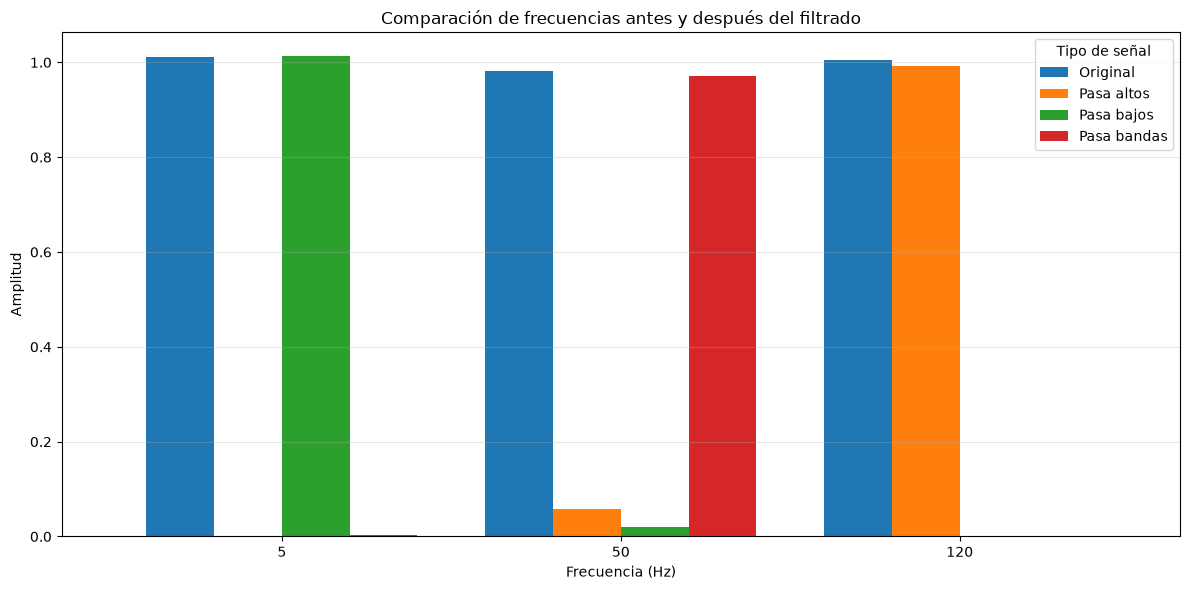

In [22]:

# =====================================================
# 23. COMPARACIÓN GRÁFICA DE COMPONENTES FRECUENCIALES
# =====================================================

tabla_grafica = tabla_fft.pivot(
    index="Frecuencia (Hz)",
    columns="Señal",
    values="Amplitud"
)

# Crear gráfica de barras
tabla_grafica.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Comparación de frecuencias antes y después del filtrado")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xticks(rotation=0)
plt.legend(title="Tipo de señal")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



# 12. Evaluación de la atenuación de frecuencias

Para evaluar la efectividad de los filtros digitales se calculará el porcentaje de atenuación de las componentes frecuenciales después del filtrado.

Se compararán las amplitudes obtenidas mediante la FFT de la señal original y las señales filtradas.

Este procedimiento permitirá identificar qué porcentaje de cada frecuencia fue reducido por los filtros implementados.


In [23]:

# =====================================================
# 24. CÁLCULO DEL PORCENTAJE DE ATENUACIÓN
# =====================================================

# Obtener amplitudes de la señal original
amplitudes_originales = tabla_grafica["Original"]

# Crear tabla para almacenar las atenuaciones
tabla_atenuacion = pd.DataFrame(index=tabla_grafica.index)

# Calcular atenuación de cada filtro
for nombre_filtro in ["Pasa bajos", "Pasa altos", "Pasa bandas"]:

    tabla_atenuacion[nombre_filtro] = (
        1 - tabla_grafica[nombre_filtro] / amplitudes_originales
    ) * 100

# Mostrar resultados
print("PORCENTAJE DE ATENUACIÓN POR FRECUENCIA")

display(tabla_atenuacion.round(2))


PORCENTAJE DE ATENUACIÓN POR FRECUENCIA


,Pasa bajos,Pasa altos,Pasa bandas
Frecuencia (Hz),,,
5,-0.05,99.92,99.67
50,98.05,94.03,0.92
120,99.85,1.27,99.94



# 13. Conclusiones generales

Durante el desarrollo de esta actividad se logró diseñar, implementar y evaluar tres tipos de filtros digitales: pasa bajos, pasa altos y pasa bandas, utilizando Python y las librerías NumPy, SciPy, Matplotlib y Pandas.

Mediante la generación de una señal compuesta por frecuencias de 5 Hz, 50 Hz y 120 Hz, junto con ruido blanco, fue posible comprobar el comportamiento de cada filtro y observar sus efectos sobre la señal original.

El filtro pasa bajos permitió conservar principalmente la frecuencia de 5 Hz, atenuando las componentes de 50 Hz y 120 Hz. El filtro pasa altos conservó principalmente la frecuencia de 120 Hz, mientras que el filtro pasa bandas permitió seleccionar la frecuencia de 50 Hz dentro del intervalo establecido de 40 a 60 Hz.

Las gráficas en el dominio del tiempo permitieron observar los cambios producidos por cada filtro. Por otra parte, las respuestas en frecuencia y el análisis mediante la Transformada Rápida de Fourier (FFT) permitieron comprobar qué componentes fueron conservadas y cuáles fueron atenuadas.

La evaluación cuantitativa mediante valores RMS mostró que la señal original presentó un valor de 1.3203, mientras que las señales filtradas obtuvieron valores de 0.7262 para el pasa bajos, 0.8370 para el pasa altos y 0.6955 para el pasa bandas.

También se comprobó que cada filtro cumple una función específica dentro del procesamiento digital de señales, por lo que su elección depende de las frecuencias que se desean conservar o eliminar.

Finalmente, esta práctica permitió comprender la importancia de los filtros digitales en el procesamiento de señales, así como aplicar herramientas de programación para analizar, visualizar y evaluar resultados mediante simulaciones computacionales.
